<a href="https://colab.research.google.com/github/SiBaekLee/Linear-Algebra/blob/main/%EC%84%A0%ED%98%95%EB%8C%80%EC%88%98%ED%95%99_Tiefighter_%EA%B5%AC%ED%98%84%EA%B3%BC%EC%A0%9C_%EC%99%84%EC%84%B1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 라이브러리 선언

In [52]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

INF = 1000  # 그림판 크기
LEN = 100   # 처음 사각형의 크기

### 축 그리기 및 사각형 그리기

In [53]:
def draw_axis(ax):
  ax.axhline(0, color='black', alpha=0.3)  # x-axis line
  ax.axvline(0, color='black', alpha=0.3)  # y-axis line
  ax.set_xlim(-INF, INF)
  ax.set_ylim(-INF, INF)
  ax.set_aspect('equal')  # 정사각형 모양으로 backboard 그리기

In [54]:
def draw_rectangle(ax, p1, p2, p3, p4):
  my_polygon = Polygon([p1, p2, p3, p4])
  ax.add_patch(my_polygon)

In [55]:
def draw_object(ax):
  p1 = np.array([0, 0])
  p2 = np.array([LEN, 0])
  p3 = np.array([LEN, LEN])
  p4 = np.array([0, LEN])

  draw_rectangle(ax, p1, p2, p3, p4)

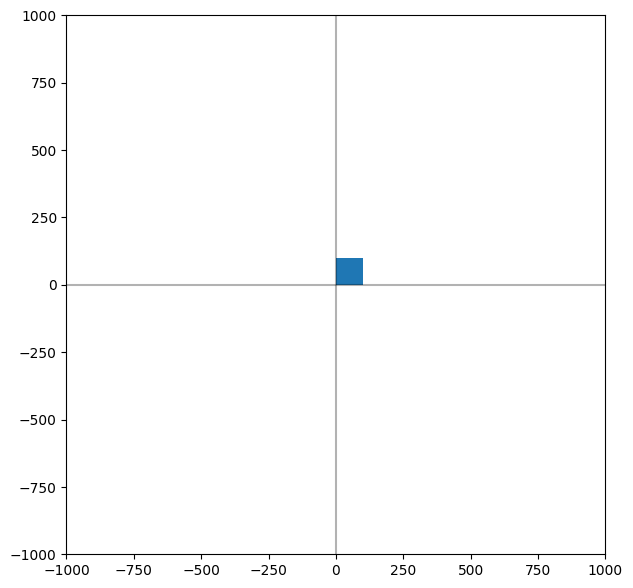

In [56]:
# 그림판 선언 및 크기 설정
fig, ax = plt.subplots(figsize=(7,7))

# 축 그리기
draw_axis(ax)

# 물체 그리기
draw_object(ax)

plt.show()

### 본론
#### 1. 변환 구현
* translate(p, dx, dy)
* rotate(p, theta)  
* scale(p, sx, sy)  
* shear_x(p, sx)  
* shear_y(p, sy)  
* reflect_x(p)  
* reflect_y(p)   
* ...

In [57]:
# 점 p를 x축 방향으로 dx만큼, y축 방향으로 dy만큼 이동시킨 점 q를 구할 것
# q = T(dx, dy) p1
def translate(p, dx, dy):
  # 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. 이동 변환 행렬 생성
  m = np.array([[1.0, 0.0, dx], [0.0, 1.0, dy], [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)  # (3,3) x (3,1) -> (3,1)
  #print(q)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0], q[1]])
  return q

In [58]:
def rotate(p, theta):
    hp = np.array([p[0], p[1], 1.0])

    # 2D Rotation Matrix in Homogeneous Coordinates
    m = np.array([[np.cos(theta), -np.sin(theta), 0.0],
                  [np.sin(theta),  np.cos(theta), 0.0],
                  [0.0,            0.0,           1.0]])

    q = np.dot(m, hp)
    q = np.array([q[0], q[1]])
    return q

In [59]:
def scale(p, sx, sy):
    hp = np.array([p[0], p[1], 1.0])

    # 2D Scaling Matrix in Homogeneous Coordinates
    m = np.array([[sx, 0.0, 0.0],
                  [0.0, sy, 0.0],
                  [0.0, 0.0, 1.0]])

    q = np.dot(m, hp)
    q = np.array([q[0], q[1]])
    return q

In [60]:
def shear_x(p, sx):
    hp = np.array([p[0], p[1], 1.0])
    m = np.array([[1.0, sx,  0.0],
                  [0.0, 1.0, 0.0],
                  [0.0, 0.0, 1.0]])
    q = np.dot(m, hp)
    return np.array([q[0], q[1]])

def shear_y(p, sy):
    hp = np.array([p[0], p[1], 1.0])
    m = np.array([[1.0, 0.0, 0.0],
                  [sy,  1.0, 0.0],
                  [0.0, 0.0, 1.0]])
    q = np.dot(m, hp)
    return np.array([q[0], q[1]])

def reflect_x(p):
    hp = np.array([p[0], p[1], 1.0])
    m = np.array([[1.0,  0.0, 0.0],
                  [0.0, -1.0, 0.0],
                  [0.0,  0.0, 1.0]])
    q = np.dot(m, hp)
    return np.array([q[0], q[1]])

def reflect_y(p):
    hp = np.array([p[0], p[1], 1.0])
    m = np.array([[-1.0, 0.0, 0.0],
                  [0.0,  1.0, 0.0],
                  [0.0,  0.0, 1.0]])
    q = np.dot(m, hp)
    return np.array([q[0], q[1]])

def reflect_origin(p):
    hp = np.array([p[0], p[1], 1.0])
    m = np.array([[-1.0,  0.0, 0.0],
                  [0.0, -1.0, 0.0],
                  [0.0,  0.0, 1.0]])
    q = np.dot(m, hp)
    return np.array([q[0], q[1]])

def reflect_yx(p):
    hp = np.array([p[0], p[1], 1.0])
    m = np.array([[0.0, 1.0, 0.0],
                  [1.0, 0.0, 0.0],
                  [0.0, 0.0, 1.0]])
    q = np.dot(m, hp)
    return np.array([q[0], q[1]])

#### 2. 파트 그리기
* draw_cockpit(p1, p2, p3, p4)    # 중앙 조종석
* draw_left_arm(p1, p2, p3, p4)   # 왼쪽 날개축
* draw_left_wing(p1, p2, p3, p4)  # 왼쪽 날개
* draw_right_arm(p1, p2, p3, p4)  # 오른쪽 날개축
* draw_right_wing(p1, p2, p3, p4) # 오른쪽 날개

In [61]:
def draw_cockpit(ax, p1, p2, p3, p4):  # 중앙 조종석
  # 1. 사각형을 원점으로 이동 변환: T(-LEN/2, -LEN/2)
  # q = T(-LEN/2, -LEN/2)p
  q1 = translate(p1, -LEN/2, -LEN/2)
  q2 = translate(p2, -LEN/2, -LEN/2)
  q3 = translate(p3, -LEN/2, -LEN/2)
  q4 = translate(p4, -LEN/2, -LEN/2)


  # 2. 크기 변환: S(5, 5)
  s = 5
  q1 = scale(q1, s, s)
  q2 = scale(q2, s, s)
  q3 = scale(q3, s, s)
  q4 = scale(q4, s, s)

  # 3. 회전 변환: R(pi/4)
  q1 = rotate(q1, 3.14/4.0)
  q2 = rotate(q2, 3.14/4.0)
  q3 = rotate(q3, 3.14/4.0)
  q4 = rotate(q4, 3.14/4.0)


  # 4. polygon 그리기
  draw_rectangle(ax, q1, q2, q3, q4)

In [62]:
def draw_left_arm(ax, p1, p2, p3, p4):
    # 원점 정렬 및 변환
    q1, q2, q3, q4 = [translate(p, -LEN/2, -LEN/2) for p in [p1, p2, p3, p4]]
    # x축 방향으로 얇고 길게 스케일링
    q1, q2, q3, q4 = [scale(q, 3.5, 0.5) for q in [q1, q2, q3, q4]]
    # 왼쪽으로 이동
    q1, q2, q3, q4 = [translate(q, -300, 0) for q in [q1, q2, q3, q4]]
    draw_rectangle(ax, q1, q2, q3, q4)

def draw_right_arm(ax, p1, p2, p3, p4):
    # 원점 정렬 및 변환
    q1, q2, q3, q4 = [translate(p, -LEN/2, -LEN/2) for p in [p1, p2, p3, p4]]
    q1, q2, q3, q4 = [scale(q, 3.5, 0.5) for q in [q1, q2, q3, q4]]
    # 오른쪽으로 이동
    q1, q2, q3, q4 = [translate(q, 300, 0) for q in [q1, q2, q3, q4]]
    draw_rectangle(ax, q1, q2, q3, q4)

def draw_left_wing(ax, p1, p2, p3, p4):
    # 원점 정렬 및 변환
    q1, q2, q3, q4 = [translate(p, -LEN/2, -LEN/2) for p in [p1, p2, p3, p4]]
    # 세로로 긴 날개 모양 스케일링
    q1, q2, q3, q4 = [scale(q, 1.0, 8.0) for q in [q1, q2, q3, q4]]
    # 왼쪽 끝으로 이동
    q1, q2, q3, q4 = [translate(q, -450, 0) for q in [q1, q2, q3, q4]]
    draw_rectangle(ax, q1, q2, q3, q4)

def draw_right_wing(ax, p1, p2, p3, p4):
    # 원점 정렬 및 변환
    q1, q2, q3, q4 = [translate(p, -LEN/2, -LEN/2) for p in [p1, p2, p3, p4]]
    q1, q2, q3, q4 = [scale(q, 1.0, 8.0) for q in [q1, q2, q3, q4]]
    # 오른쪽 끝으로 이동
    q1, q2, q3, q4 = [translate(q, 450, 0) for q in [q1, q2, q3, q4]]
    draw_rectangle(ax, q1, q2, q3, q4)

In [63]:
# 2. tiefigher 그리기
def draw_object(ax):
  p1 = np.array([0, 0])
  p2 = np.array([LEN, 0])
  p3 = np.array([LEN, LEN])
  p4 = np.array([0, LEN])

  # 1. 중앙 조종석 그리기
  draw_cockpit(ax, p1, p2, p3, p4)

In [64]:
def draw_object(ax):
  p1 = np.array([0, 0])
  p2 = np.array([LEN, 0])
  p3 = np.array([LEN, LEN])
  p4 = np.array([0, LEN])

  # 1. 중앙 조종석 그리기
  draw_cockpit(ax, p1, p2, p3, p4)

  # 2. 좌우 날개축 그리기
  draw_left_arm(ax, p1, p2, p3, p4)
  draw_right_arm(ax, p1, p2, p3, p4)

  # 3. 좌우 날개 그리기
  draw_left_wing(ax, p1, p2, p3, p4)
  draw_right_wing(ax, p1, p2, p3, p4)

#### 변환 함수 확인
* 구현한 변환 함수들이 제대로 동작하는지 점 하나로 먼저 확인해 본다.
* (1) translate, (2) rotate, (3) scale, (4) shear_x, (5) shear_y, (6) reflect_x, (7) reflect_y, (8) 원점 반전, (9) y=x 반전

In [65]:
# 테스트용 점 하나 (2, 1)
t = np.array([2, 1])

print("translate(3, 4)  :", translate(t, 3, 4))       # (5, 5)
print("rotate(90도)     :", rotate(t, np.pi/2))        # (-1, 2)
print("scale(2, 3)      :", scale(t, 2, 3))            # (4, 3)
print("shear_x(0.5)     :", shear_x(t, 0.5))           # (2.5, 1)
print("shear_y(0.5)     :", shear_y(t, 0.5))           # (2, 2)
print("reflect_x        :", reflect_x(t))              # (2, -1)
print("reflect_y        :", reflect_y(t))              # (-2, 1)
print("reflect_origin   :", reflect_origin(t))         # (-2, -1)
print("reflect_yx (y=x) :", reflect_yx(t))             # (1, 2)

translate(3, 4)  : [5. 5.]
rotate(90도)     : [-1.  2.]
scale(2, 3)      : [4. 3.]
shear_x(0.5)     : [2.5 1. ]
shear_y(0.5)     : [2. 2.]
reflect_x        : [ 2. -1.]
reflect_y        : [-2.  1.]
reflect_origin   : [-2. -1.]
reflect_yx (y=x) : [1. 2.]


#### 2-1. 파트 그리기
* 그림을 보면 날개축은 가운데로 갈수록 위로 올라가는 모양이고, 날개는 바깥쪽이 더 긴 사다리꼴이다.
  * 날개축: 직사각형을 shear_y로 기울인 평행사변형 + 그걸 reflect_x로 뒤집은 것
  * 날개: 직사각형을 shear_y로 기울인 평행사변형 + 그걸 reflect_x로 뒤집은 것
  * 오른쪽은 왼쪽을 reflect_y로 뒤집어서 그린다.

In [66]:
def draw_left_arm(ax, p1, p2, p3, p4):
    # 1. 사각형을 원점으로 이동: T(-LEN/2, -LEN/2)
    q1, q2, q3, q4 = [translate(p, -LEN/2, -LEN/2) for p in [p1, p2, p3, p4]]
    # 2. 크기 변환: 가로 600, 세로 80 -> S(6, 0.8)
    q1, q2, q3, q4 = [scale(q, 6.0, 0.8) for q in [q1, q2, q3, q4]]
    # 3. y방향 기울이기: 오른쪽(가운데)으로 갈수록 위로 올라가게
    q1, q2, q3, q4 = [shear_y(q, 0.1) for q in [q1, q2, q3, q4]]
    # 4. 왼쪽으로 이동: T(-550, 35)
    q1, q2, q3, q4 = [translate(q, -550, 35) for q in [q1, q2, q3, q4]]
    # 5. 위쪽 조각 그리기
    draw_rectangle(ax, q1, q2, q3, q4)

    # 6. x축 반전해서 아래쪽 조각 그리기
    r1, r2, r3, r4 = [reflect_x(q) for q in [q1, q2, q3, q4]]
    draw_rectangle(ax, r1, r2, r3, r4)

def draw_right_arm(ax, p1, p2, p3, p4):
    # 왼쪽 날개축과 똑같이 만든 다음 y축 반전으로 오른쪽으로 보냄
    q1, q2, q3, q4 = [translate(p, -LEN/2, -LEN/2) for p in [p1, p2, p3, p4]]
    q1, q2, q3, q4 = [scale(q, 6.0, 0.8) for q in [q1, q2, q3, q4]]
    q1, q2, q3, q4 = [shear_y(q, 0.1) for q in [q1, q2, q3, q4]]
    q1, q2, q3, q4 = [translate(q, -550, 35) for q in [q1, q2, q3, q4]]

    # y축 반전 -> 오른쪽 위쪽 조각
    q1, q2, q3, q4 = [reflect_y(q) for q in [q1, q2, q3, q4]]
    draw_rectangle(ax, q1, q2, q3, q4)

    # x축 반전 -> 오른쪽 아래쪽 조각
    r1, r2, r3, r4 = [reflect_x(q) for q in [q1, q2, q3, q4]]
    draw_rectangle(ax, r1, r2, r3, r4)

def draw_left_wing(ax, p1, p2, p3, p4):
    # 1. 사각형을 원점으로 이동
    q1, q2, q3, q4 = [translate(p, -LEN/2, -LEN/2) for p in [p1, p2, p3, p4]]
    # 2. 세로로 길게: 가로 100, 세로 600 -> S(1, 6)
    q1, q2, q3, q4 = [scale(q, 1.0, 6.0) for q in [q1, q2, q3, q4]]
    # 3. y방향 기울이기: 오른쪽으로 갈수록 아래로 내려가게 (사다리꼴 느낌)
    q1, q2, q3, q4 = [shear_y(q, -2.0) for q in [q1, q2, q3, q4]]
    # 4. 왼쪽 끝으로 이동: T(-800, 200)
    q1, q2, q3, q4 = [translate(q, -800, 200) for q in [q1, q2, q3, q4]]
    # 5. 위쪽 조각 그리기
    draw_rectangle(ax, q1, q2, q3, q4)

    # 6. x축 반전해서 아래쪽 조각 그리기
    r1, r2, r3, r4 = [reflect_x(q) for q in [q1, q2, q3, q4]]
    draw_rectangle(ax, r1, r2, r3, r4)

def draw_right_wing(ax, p1, p2, p3, p4):
    # 왼쪽 날개와 똑같이 만든 다음 y축 반전으로 오른쪽으로 보냄
    q1, q2, q3, q4 = [translate(p, -LEN/2, -LEN/2) for p in [p1, p2, p3, p4]]
    q1, q2, q3, q4 = [scale(q, 1.0, 6.0) for q in [q1, q2, q3, q4]]
    q1, q2, q3, q4 = [shear_y(q, -2.0) for q in [q1, q2, q3, q4]]
    q1, q2, q3, q4 = [translate(q, -800, 200) for q in [q1, q2, q3, q4]]

    # y축 반전 -> 오른쪽 위쪽 조각
    q1, q2, q3, q4 = [reflect_y(q) for q in [q1, q2, q3, q4]]
    draw_rectangle(ax, q1, q2, q3, q4)

    # x축 반전 -> 오른쪽 아래쪽 조각
    r1, r2, r3, r4 = [reflect_x(q) for q in [q1, q2, q3, q4]]
    draw_rectangle(ax, r1, r2, r3, r4)

#### 2-2. TIE Fighter 최종 그리기
* draw_object()는 위에서 만든 것과 동일하게 파트 함수들을 호출한다. (조종석 -> 날개축 -> 날개)

In [67]:
def draw_object(ax):
  p1 = np.array([0, 0])
  p2 = np.array([LEN, 0])
  p3 = np.array([LEN, LEN])
  p4 = np.array([0, LEN])

  # 1. 중앙 조종석 그리기
  draw_cockpit(ax, p1, p2, p3, p4)

  # 2. 좌우 날개축 그리기
  draw_left_arm(ax, p1, p2, p3, p4)
  draw_right_arm(ax, p1, p2, p3, p4)

  # 3. 좌우 날개 그리기
  draw_left_wing(ax, p1, p2, p3, p4)
  draw_right_wing(ax, p1, p2, p3, p4)

### 3. main

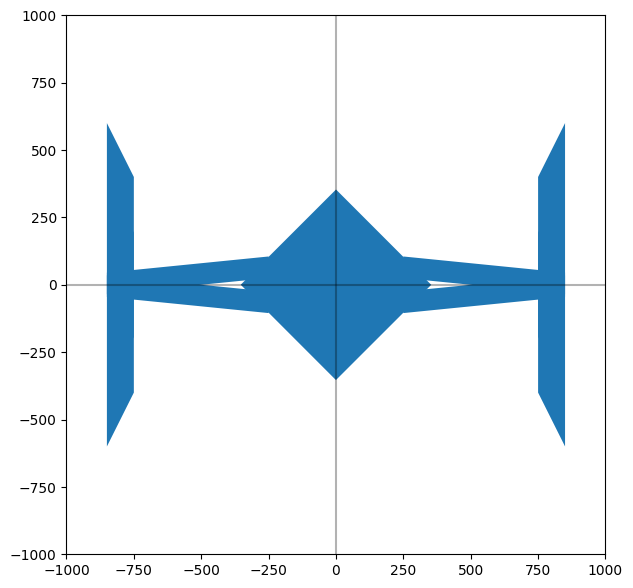

In [68]:
# 그림판 선언 및 크기 설정
fig, ax = plt.subplots(figsize=(7,7))

# 축 그리기
draw_axis(ax)

# 물체 그리기
draw_object(ax)

plt.show()